In [1]:
import pytometry as pm
import os
import anndata
from pathlib import Path
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from scipy.stats import spearmanr, mannwhitneyu
from trafficking_inference.CellVADIS import Stitch_OT, Joint_OT
import umap
import pandas as pd
from scipy.stats import zscore
from trafficking_inference.helper_functions import (
    plot_fate_probabilities_with_pie_charts,
)

plt.style.use("default")

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial"],
        "font.size": 6,
        "axes.titlesize": 7,
        "axes.labelsize": 6,
        "axes.linewidth": 0.8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "legend.fontsize": 6,
        "legend.frameon": False,
        "lines.linewidth": 1.2,
        "lines.markersize": 4,
        "figure.figsize": (3.5, 2.6),
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "savefig.bbox": "standard",
        # "savefig.pad_inches": 0.02,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)


cm = 1 / 2.54  # centimeters in inches
path_data = "data/Wongetal/CD4/"
figure_path = "data/figures/Wongetal/CD4/allmarkers_StitchOT/StitchOT_"


if not os.path.exists(figure_path):
    os.makedirs(figure_path)
use_Stitch = True
keep_columns = [
    "CD29",
    "CD62L",
    "CLA",
    "CD103",
    "CCR4",
    "CD49a",
    "CCR10",
    "CXCR6",
    "CCR9",
    "CXCR3",
    "CD31",
    "CXCR5",
    "CD49d",
    "CCR2",
    "IntegrinB7",
    "CCR5",
    "CCR6",
    "CCR7",
    "CX3CR1",
    "CXCR4",
    "CD69",
    "CD25",
    "CD45RO",
    "CD27",
    "ICOS",
    "PD-1",
    "CD161",
    "CD95",
    "CD45RA",
    "CD127",
]


columns_order = [
    "CCR2",
    "CCR4",
    "CCR5",
    "CCR6",
    "CCR7",
    "CCR9",
    "CCR10",
    "CD29",
    "CD31",
    "CD103",
    "CD62L",
    "CD49a",
    "CD49d",
    "CLA",
    "CXCR3",
    "CXCR4",
    "CXCR5",
    "CXCR6",
    "CX3CR1",
    "IntegrinB7",
]
columns_order_diff = [
    "CD25",
    "CD27",
    "CD45RA",
    "CD45RO",
    "CD69",
    "CD95",
    "CD127",
    "CD161",
    "ICOS",
    "PD-1",
]
all_columns_order = columns_order + columns_order_diff
tissue_colors = {
    "Tonsil": "#0072B2",
    "Spleen": "#E69F00",
    "Colon": "#009E73",
    "Skin": "#fbafe4",
    "Lung": "#F0E442",  # d4aaab "#F0E442"
    "Liver": "mediumpurple",  # 674C47  #6C2E1F   "#8e603e"  #ca9161
}

adata_stack = []
files = [str(f) for f in Path(path_data).glob("*.fcs")]
# dont load files that have CB in the name
files = [f for f in files if "CB" not in f]
sample_ids = [f.split("_")[1] for f in files]
for file, file_id in zip(files, sample_ids, strict=False):
    adata = pm.io.read_fcs(file)
    if file_id is not None:
        adata.obs["sample"] = file_id

    # delete all columns that are duplicates in the adata.var_names
    duplicate_columns = [
        col for col in adata.var_names if list(adata.var_names).count(col) > 1
    ]
    adata = adata[:, ~adata.var_names.isin(duplicate_columns)]
    # now keep only the columns that are in the keep_columns list
    adata = adata[:, adata.var_names.isin(all_columns_order)]
    # reorder the columns in the adata.var_names to match the order in the all_columns_order list
    adata = adata[:, [col for col in all_columns_order if col in adata.var_names]]
    adata_stack.append(adata)

adata = anndata.concat(adata_stack, join="outer", uns_merge="unique", index_unique="-")

# .obs sample column should be split into two columns, first should be the sample id and second should be tissue type
# they are currently stored as Tissuesampleid
adata.obs[["tissue", "sample_id"]] = adata.obs["sample"].str.extract(
    r"([A-Za-z]+)(\d+)"
)
# get number of cells per tissue
print(adata.obs["tissue"].value_counts())


def obs_key_wise_subsampling(adata, obs_keys, N, random_state=0):
    """
    Subsample to exactly N cells per group defined by obs_keys.
    Example: obs_keys=["timepoint", "location"] -> N cells for each (timepoint, location).
    """
    if isinstance(obs_keys, str):
        obs_keys = [obs_keys]

    group_sizes = adata.obs.groupby(obs_keys).size()
    too_small = group_sizes[group_sizes < N]
    if len(too_small) > 0:
        print("Subsample size to large, using minimum group size of", too_small.min())
        N = too_small.min()

    rng = np.random.default_rng(random_state)
    sampled_indices = []

    for _, df_group in adata.obs.groupby(obs_keys):
        # except PBMC, where we subsample to 50k cells
        if "PBMC" in df_group[obs_keys[0]].values:
            if len(df_group) < 10000:
                sampled_indices.append(df_group.index.to_numpy())
                continue
            else:
                sampled_indices.append(
                    rng.choice(df_group.index.to_numpy(), size=10000, replace=False)
                )
                continue
        sampled_indices.append(
            rng.choice(df_group.index.to_numpy(), size=N, replace=False)
        )

    selection = np.concatenate(sampled_indices)
    return adata[selection].copy()


# remove cells with marker values above the 99th percentile of the respective marker
# adata = adata[~np.any(adata.X > np.percentile(adata.X, 99, axis=0), axis=1)]
adata = obs_key_wise_subsampling(adata, ["tissue"], 10000, random_state=0)
# normalize data with z-score normalization
# remove cells with extreme marker values

adata.obsm["X_zscore"] = zscore(adata.X, axis=1)
# Compute z-score normalization across each cell (row-wise), to get relative expression levels per cell
adata.layers["X_zscore"] = adata.obsm["X_zscore"]
print(adata.obs["tissue"].value_counts())

/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wic

tissue
PBMC      175132
Tonsil    154107
Liver     115931
Skin       61641
Spleen     57479
Lung       33826
Colon      26974
Name: count, dtype: int64
tissue
Colon     10000
Liver     10000
Lung      10000
PBMC      10000
Skin      10000
Spleen    10000
Tonsil    10000
Name: count, dtype: int64


Plot CD69 expression between CD4 and CD8 subsets for different tissues

In [2]:
path_data_CD4 = "data/Wongetal/CD4/"
adata_stack_CD4 = []
files = [str(f) for f in Path(path_data_CD4).glob("*.fcs")]
# dont load files that have CB in the name
files = [f for f in files if "CB" not in f]
sample_ids = [f.split("_")[1] for f in files]
for file, file_id in zip(files, sample_ids, strict=False):
    adata_CD4 = pm.io.read_fcs(file)
    if file_id is not None:
        adata_CD4.obs["sample"] = file_id
    # delete all columns that are duplicates in the adata.var_names
    duplicate_columns = [
        col for col in adata_CD4.var_names if list(adata_CD4.var_names).count(col) > 1
    ]
    adata_CD4 = adata_CD4[:, ~adata_CD4.var_names.isin(duplicate_columns)]
    # now keep only the columns that are in the keep_columns list
    adata_CD4 = adata_CD4[:, adata_CD4.var_names.isin(all_columns_order)]
    # reorder the columns in the adata.var_names to match the order in the all_columns_order list
    adata_CD4 = adata_CD4[
        :, [col for col in all_columns_order if col in adata_CD4.var_names]
    ]
    adata_stack_CD4.append(adata_CD4)

adata_CD4 = anndata.concat(
    adata_stack_CD4, join="outer", uns_merge="unique", index_unique="-"
)
# .obs sample column should be split into two columns, first should be the sample id and second should be tissue type
# they are currently stored as Tissuesampleid
adata_CD4.obs[["tissue", "sample_id"]] = adata_CD4.obs["sample"].str.extract(
    r"([A-Za-z]+)(\d+)"
)
# get number of cells per tissue
adata_CD4 = obs_key_wise_subsampling(adata_CD4, ["tissue"], 10000, random_state=0)
adata_CD4.obsm["X_zscore"] = zscore(adata_CD4.X, axis=1)
adata_CD4.layers["X_zscore"] = adata_CD4.obsm["X_zscore"]

/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/wickerlw/.pyenv/versions/3.12.11/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transform

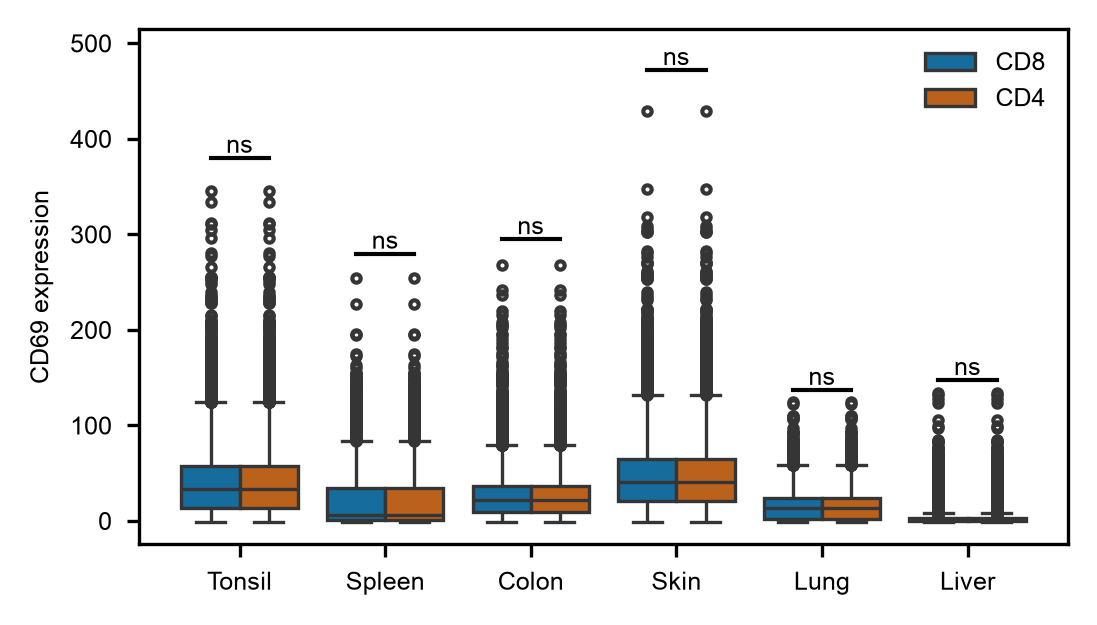

In [3]:
# get CD69 expression in each tissue and plot as one grouped violin plot
plot_df_cd8 = pd.DataFrame(
    {
        "tissue": adata.obs["tissue"].to_numpy(),
        "CD69": adata.X[:, adata.var_names.get_loc("CD69")],
        "dataset": "CD8",
    }
)
plot_df_cd4 = pd.DataFrame(
    {
        "tissue": adata_CD4.obs["tissue"].to_numpy(),
        "CD69": adata_CD4.X[:, adata_CD4.var_names.get_loc("CD69")],
        "dataset": "CD4",
    }
)

plot_df = pd.concat([plot_df_cd8, plot_df_cd4], ignore_index=True)
plot_df["tissue"] = pd.Categorical(
    plot_df["tissue"],
    categories=["Tonsil", "Spleen", "Colon", "Skin", "Lung", "Liver"],
    ordered=True,
)

fig, ax = plt.subplots(figsize=(9 * cm, 5 * cm), layout="constrained")
sns.boxplot(
    data=plot_df,
    x="tissue",
    y="CD69",
    hue="dataset",
    order=["Tonsil", "Spleen", "Colon", "Skin", "Lung", "Liver"],
    hue_order=["CD8", "CD4"],
    palette={"CD8": "#0072B2", "CD4": "#D55E00"},
    # cut=0,
    ax=ax,
    linewidth=0.8,
    fliersize=2,
    # inner="quart",
)

# compute pairwise Mann-Whitney U test between CD8 and CD4 for each tissue and add significance stars to the plot

for tissue in ["Tonsil", "Spleen", "Colon", "Skin", "Lung", "Liver"]:
    cd8_values = plot_df[(plot_df["tissue"] == tissue) & (plot_df["dataset"] == "CD8")][
        "CD69"
    ]
    cd4_values = plot_df[(plot_df["tissue"] == tissue) & (plot_df["dataset"] == "CD4")][
        "CD69"
    ]
    stat, p_value = mannwhitneyu(cd8_values, cd4_values, alternative="two-sided")
    if p_value < 0.001:
        significance = "***"
    elif p_value < 0.01:
        significance = "**"
    elif p_value < 0.05:
        significance = "*"
    else:
        significance = "ns"
    # add significance stars to the plot
    y_max = max(cd8_values.max(), cd4_values.max())
    y_min = min(cd8_values.min(), cd4_values.min())
    y, h, col = y_max + (y_max - y_min) * 0.1, (y_max - y_min) * 0.0, "k"
    ax.plot(
        [
            ["Tonsil", "Spleen", "Colon", "Skin", "Lung", "Liver"].index(tissue) - 0.2,
            ["Tonsil", "Spleen", "Colon", "Skin", "Lung", "Liver"].index(tissue) + 0.2,
        ],
        [y, y],
        lw=1,
        c=col,
    )
    ax.text(
        ["Tonsil", "Spleen", "Colon", "Skin", "Lung", "Liver"].index(tissue),
        y + h,
        significance,
        ha="center",
        va="bottom",
        color=col,
    )
ax.set_ylim(None, plot_df["CD69"].max() * 1.2)
ax.set_xlabel("")
ax.set_ylabel("CD69 expression")
ax.legend(title="", frameon=False)
plt.savefig(figure_path + "CD69_expression_CD8_CD4.pdf", dpi=300, bbox_inches="tight")

import scanpy as sc

sc.pp.neighbors(adata, n_neighbors=30, use_rep='X_zscore')
sc.tl.umap(adata)

ax = sc.pl.umap(adata, color=['sample_id', 'tissue'], wspace=0.1, show=False, s=10)

plt.show()
ax = sc.pl.umap(adata, color=adata.var_names.tolist(),
                wspace=0.1, show=False, s=10, layer='X_zscore')
plt.show()

# CellVADIS

In [4]:
source_name = "PBMC"
replicate_id = None
# if adata has too many cells, subsample to 50k cells
if adata.shape[0] > 100000:
    adata_OT = sc.pp.subsample(adata, n_obs=100000, random_state=3, copy=True)
else:
    adata_OT = adata.copy()
if replicate_id is not None:
    adata_OT = adata_OT[adata_OT.obs["sample_id"] == replicate_id]
mask_source = adata_OT.obs["tissue"] == source_name
mask_target = adata_OT.obs["tissue"] != source_name

data_source = adata_OT[mask_source].obsm["X_zscore"].copy()
data_target = adata_OT[mask_target].obsm["X_zscore"].copy()
# check that no values are nans
print("Checking for NaN values in source and target data...")
if np.isnan(data_source).any():
    print("Warning: NaN values found in source data. Replacing with 0.")
    data_source = np.nan_to_num(data_source, nan=0.0)
if np.isnan(data_target).any():
    print("Warning: NaN values found in target data. Replacing with 0.")
    data_target = np.nan_to_num(data_target, nan=0.0)
target_locations = adata_OT[mask_target].obs["tissue"].values

# target_names are all except source_name
target_names = adata_OT.obs["tissue"].unique().tolist()
target_names.remove(source_name)
print("Target names:", target_names)

if use_Stitch:
    fate_matrix_with_unsampled, coupling_matrix, OT_plan, selected_target_mask = (
        Stitch_OT(
            data_source.astype(np.float64),
            data_target.astype(np.float64),
            target_locations,
            target_names,
            tau_a=0.5,
            subsample_non_blood=True,
            rescale_OT_plans=True,
            ignore_warnings=False,
            random_seed=42,
            cost_scaling="median",
            epsilon=0.005,
            cost_metric="euclidean",
            assign_unsampled_probs=True,
        )
    )
    fate_matrix = fate_matrix_with_unsampled[:, :-1] / np.sum(
        fate_matrix_with_unsampled[:, :-1], axis=1, keepdims=True
    )

else:
    print("Using Joint OT")
    fate_matrix, coupling_matrix, OT_plan, selected_target_mask = Joint_OT(
        data_source.astype(np.float64),
        data_target.astype(np.float64),
        target_locations,
        target_names,
        tau_b=0.5,
        subsample_non_blood=True,
        ignore_warnings=False,
        random_seed=42,
        cost_scaling="median",
        epsilon=0.005,
        cost_metric="euclidean",
    )

# Plot fate matrix as stacked bar plot, with one bar per sample, colored by location

Checking for NaN values in source and target data...
Target names: ['Colon', 'Liver', 'Lung', 'Skin', 'Spleen', 'Tonsil']


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/ot/unbalanced/_sinkhorn.py:736: UserWarning: If reg_type = entropy, then the matrix c is overwritten by the one matrix.
  warnings.warn(


### Plot tissue-specific transition proportions

[0.04032818 0.38161155 0.04778983 0.06171485 0.14232094 0.03680662
 0.28942802]


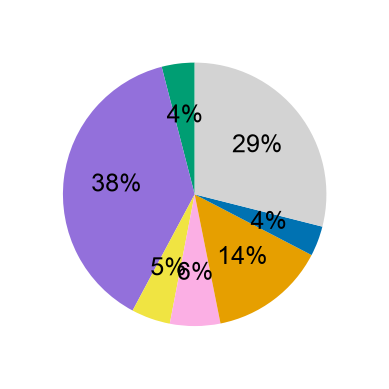

In [5]:
if use_Stitch:
    # plot tissue-specific transition proportions with fraction of unobserved cells
    tissue_colors_with_unsampled = tissue_colors.copy()
    tissue_colors_with_unsampled["Unsampled"] = "lightgrey"
    target_names_with_unsampled = target_names + ["Unsampled"]
    dominant_fate_proportions = np.sum(fate_matrix_with_unsampled, axis=0) / np.sum(
        fate_matrix_with_unsampled
    )
    print(dominant_fate_proportions)
    # Plot 2: Pie chart of dominant fates
    fig, ax = plt.subplots(figsize=(3, 3, "cm"), layout="constrained")
    colors = [
        tissue_colors_with_unsampled[tissue] for tissue in target_names_with_unsampled
    ]
    ax.pie(
        dominant_fate_proportions,
        autopct="%1.0f%%",
        startangle=90,
        colors=colors,
        pctdistance=0.6,
    )
    plt.savefig(figure_path + "dominant_fate_pie_chart_with_unobserved.pdf")
    plt.show()

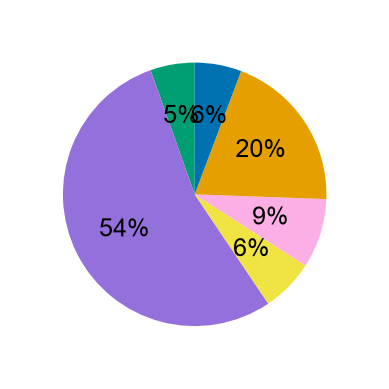

In [6]:
# Plot tissue-specific transition proportions without fraction of unobserved cells
dominant_fate_proportions = np.sum(fate_matrix, axis=0) / np.sum(fate_matrix)

# Plot 2: Pie chart of dominant fates
fig, ax = plt.subplots(figsize=(3, 3, "cm"), layout="constrained")
colors = [tissue_colors[tissue] for tissue in target_names]
ax.pie(
    dominant_fate_proportions,
    autopct="%1.0f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.6,
)
plt.savefig(figure_path + "dominant_fate_pie_chart_" + str(replicate_id) + ".pdf")
plt.show()

### Plot UMAP of blood cells colored by dominant fate and with individual resultion for a subsample of blood cells

In [7]:
adata_blood = adata_OT[mask_source].copy()
sc.pp.neighbors(adata_blood, n_neighbors=30)
sc.tl.umap(adata_blood, min_dist=0.9, spread=0.9, random_state=42)
data_source_embedded = adata_blood.obsm["X_umap"].copy()

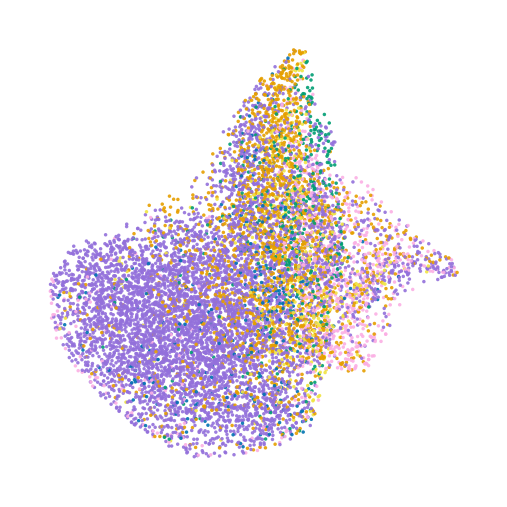

In [8]:
# color source umap by dominant fate, which is the target with the highest probability in the fate matrix
dominant_fate = np.argmax(fate_matrix, axis=1)
dominant_fate_names = [target_names[i] for i in dominant_fate]
plt.figure(figsize=(4, 4, "cm"), layout="constrained")
plt.scatter(
    data_source_embedded[:, 0],
    data_source_embedded[:, 1],
    c=[tissue_colors[tissue] for tissue in dominant_fate_names],
    s=0.7,
    edgecolor=None,
    alpha=0.9,
    linewidth=0,
    rasterized=True,
)
plt.xticks([])
plt.yticks([])
# no outlines of plot
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["bottom"].set_visible(False)
plt.gca().spines["left"].set_visible(False)
# plt.xlabel("UMAP1")
# plt.ylabel("UMAP2")
plt.savefig(figure_path + "dominant_fate_umap_" + str(replicate_id) + ".pdf", dpi=600)
plt.show()


# plot fate probabilities as pie charts on umap
fig, ax = plt.subplots(figsize=(4, 4, "cm"), layout="constrained")

plot_fate_probabilities_with_pie_charts(
    ax=ax,
    data_df=pd.DataFrame(data_source_embedded, columns=["UMAP1", "UMAP2"]),
    probability_df=pd.DataFrame(fate_matrix, columns=target_names),
    entropy_fade=False,
    background=40,
    outline=0.0,
    colors=[tissue_colors[tissue] for tissue in target_names],
    s=330,
    n_cells_to_plot=100,
    # locations=adata_blood.obs['photoconverted'].values,
    plot_legend=False,
)

plt.xticks([])
plt.yticks([])
# no outlines of plot
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["bottom"].set_visible(False)
plt.gca().spines["left"].set_visible(False)
plt.savefig(
    figure_path + "fate_probabilities_pie_chart_umap_" + str(replicate_id) + ".pdf"
)
plt.close()

# create a legend and store seperately as pdf for later use


fig, ax = plt.subplots(figsize=(5 * cm, 1.2 * cm), layout="constrained")
legend_elements = [
    Patch(color=tissue_colors[loc], label=f"{loc}")
    for i, loc in enumerate(target_names)
]
ax.legend(handles=legend_elements, title="Fate", ncol=3)
ax.axis("off")
plt.savefig(
    figure_path + "fate_legend.pdf",
    transparent=True,
)
plt.close()

## Infer trafficking signatures
### Corellate fates with marker expression for blood cells

Liver_vs_CCR7      0.506065
Liver_vs_CD95      0.459320
Liver_vs_CD45RA    0.454241
Liver_vs_CD45RO    0.448952
Liver_vs_CD62L     0.433468
Skin_vs_CLA        0.399406
Liver_vs_CD27      0.384221
Skin_vs_CCR4       0.368996
Skin_vs_CCR7       0.367005
Colon_vs_CCR9      0.365089
dtype: float64
Correlation matrix min: -0.6643269878472698
Correlation matrix max: 0.5310569513229422


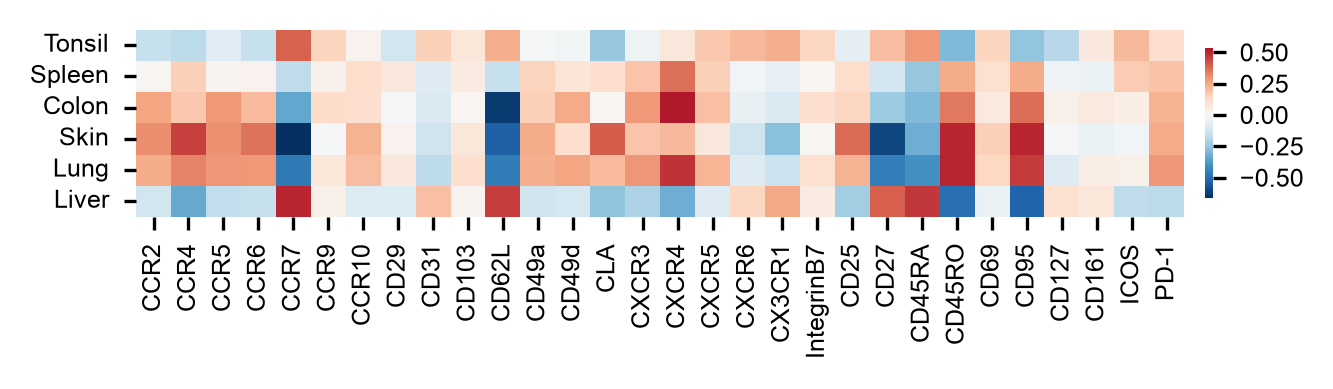

Correlation matrix min: -0.6643269878472698
Correlation matrix max: 0.5310569513229422


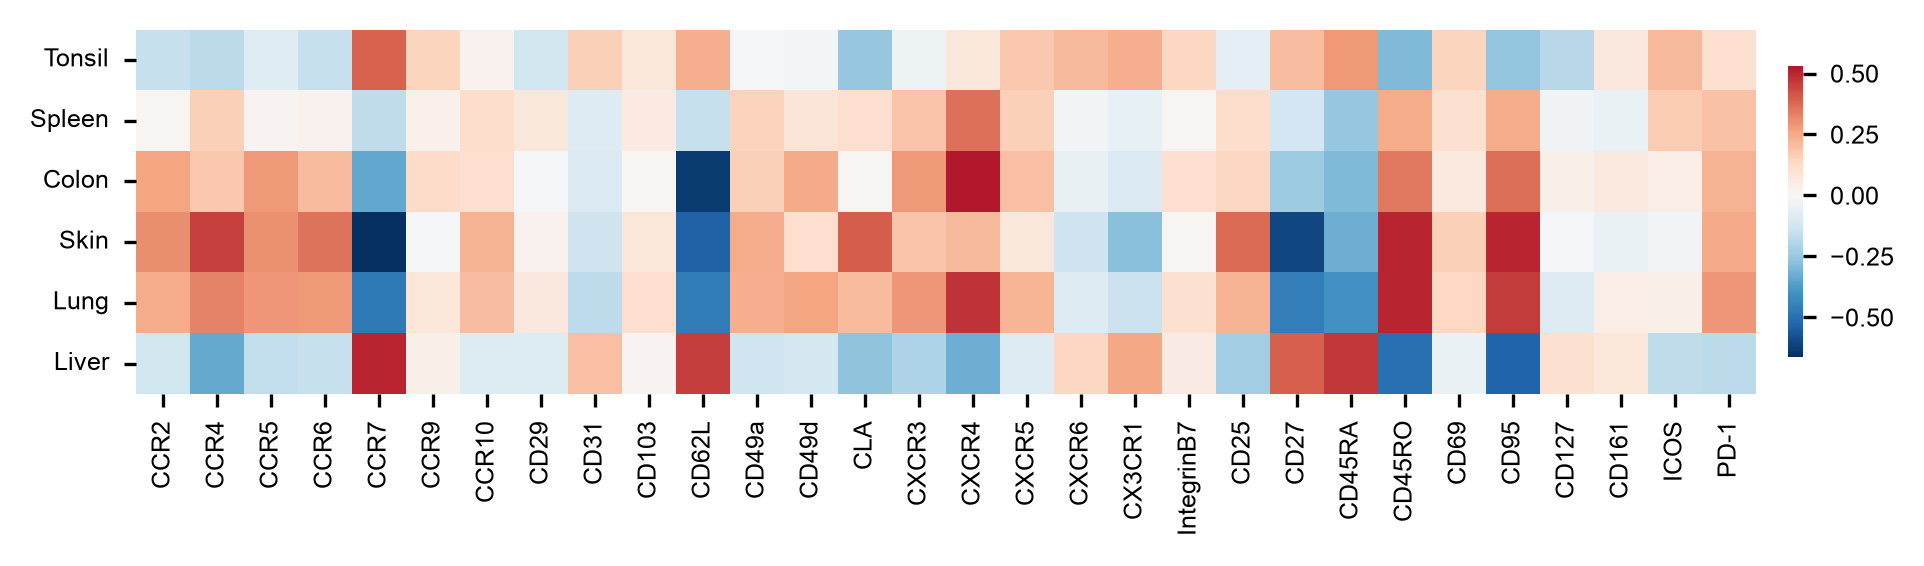

In [9]:
# Now correlate fates with marker expression in the blood data
fate_df = pd.DataFrame(fate_matrix, columns=target_names)
marker_df = pd.DataFrame(data_source, columns=adata.var_names)
# rearrange to be [Tonsil, Spleen, Colon, Skin, Lung, Liver]
fate_df = fate_df[["Tonsil", "Spleen", "Colon", "Skin", "Lung", "Liver"]]

# Compute pairwise correlations between each fate and each marker
correlation_results = {}
for fate_col in fate_df.columns:
    for marker_col in marker_df.columns:
        corr = fate_df[fate_col].corr(marker_df[marker_col])
        correlation_results[f"{fate_col}_vs_{marker_col}"] = corr

correlation_df = pd.Series(correlation_results).abs().sort_values(ascending=False)
print(correlation_df.head(10))
# Create a correlation matrix (fate x marker)
corr_matrix = np.zeros((len(fate_df.columns), len(marker_df.columns)))
for i, fate_col in enumerate(fate_df.columns):
    for j, marker_col in enumerate(marker_df.columns):
        corr_matrix[i, j] = fate_df[fate_col].corr(
            marker_df[marker_col], method="spearman"
        )

corr_matrix_df = pd.DataFrame(
    corr_matrix, index=fate_df.columns, columns=marker_df.columns
)

# Plot 1: Heatmap of correlations
# cbar ticks should be at -0.5, -0.25, 0, 0.25, 0.5
fig, ax = plt.subplots(figsize=(11, 3, "cm"), layout="constrained")  # 16, 4.5
# print min and max value of the correlation matrix
print("Correlation matrix min:", corr_matrix_df.min().min())
print("Correlation matrix max:", corr_matrix_df.max().max())
sns.heatmap(
    corr_matrix_df,
    annot=False,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    cbar_kws={"shrink": 0.8, "ticks": [-0.5, -0.25, 0, 0.25, 0.5], "pad": 0.02},
    ax=ax,
)  #'label': 'Correlation',

# ax.set_title('Correlation between Fate Probabilities and Marker Expression')
ax.set_xlabel("")
# rotate ytick labels to 45 degrees
ax.set_yticklabels(labels=ax.get_yticklabels(), rotation=0)
ax.set_xticklabels(labels=ax.get_xticklabels(), rotation=90)
ax.set_ylabel("")
plt.savefig(figure_path + "correlation_heatmap_" + str(replicate_id) + ".pdf")
plt.show()


# Plot 1: Heatmap of correlations, but with different plotsize
# cbar ticks should be at -0.5, -0.25, 0, 0.25, 0.5
fig, ax = plt.subplots(figsize=(16, 4.5, "cm"), layout="constrained")  # 16, 4.5
# print min and max value of the correlation matrix
print("Correlation matrix min:", corr_matrix_df.min().min())
print("Correlation matrix max:", corr_matrix_df.max().max())
sns.heatmap(
    corr_matrix_df,
    annot=False,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    cbar_kws={"shrink": 0.8, "ticks": [-0.5, -0.25, 0, 0.25, 0.5], "pad": 0.02},
    ax=ax,
)  #'label': 'Correlation',

# ax.set_title('Correlation between Fate Probabilities and Marker Expression')
ax.set_xlabel("")
# rotate ytick labels to 45 degrees
ax.set_yticklabels(labels=ax.get_yticklabels(), rotation=0)
ax.set_xticklabels(labels=ax.get_xticklabels(), rotation=90)
ax.set_ylabel("")
plt.savefig(figure_path + "correlation_heatmap_" + str(replicate_id) + "_large.pdf")
plt.show()

## Specific homing signature?
### Visually using umap projections

In [ ]:
# Do a Umap of colon cells
threshold = 1 / 3
# make colors a bit lighter like here: [tuple(0.9*c + 0.1 for c in color) for color in colors]
for tissue in target_names:
    # extract colon cells from adata_OT
    colon_cells = data_target[selected_target_mask][
        target_locations[selected_target_mask] == tissue
    ]
    umap_colon = umap.UMAP(
        n_neighbors=30, min_dist=0.3, spread=1, random_state=42
    ).fit_transform(colon_cells)
    # plot umap embedding of colon cells
    fig, ax = plt.subplots(figsize=(2.2, 3.4, "cm"), layout="constrained")
    ax.scatter(
        umap_colon[:, 0],
        umap_colon[:, 1],
        c="darkgray",
        s=1.5,
        alpha=0.6,
        edgecolor=None,
        linewidth=0,
        rasterized=True,
    )
    # ax.set_title('UMAP Embedding of ' + tissue + ' Cells')
    # Compute the average coordinates of all blood cells that have a fate probability greater than 0.35 for colon and plot this point on the umap
    blood_cells_fate_prob = fate_matrix[:, target_names.index(tissue)]
    # compute the average coordinates of these blood cells by multiplying the coupling matrix with the tissue cells coordinates
    blood_cells_high_fate_coupling = coupling_matrix[
        blood_cells_fate_prob > threshold, :
    ][:, target_locations[selected_target_mask] == tissue]

    # Normalize the selected weights so they sum to 1 for each blood cell.
    # Otherwise the weighted sum is a scaled affine combination and can fall outside the convex hull of the tissue coordinates.
    row_sums = blood_cells_high_fate_coupling.sum(axis=1, keepdims=True)
    normalized_weights = np.divide(
        blood_cells_high_fate_coupling,
        row_sums,
        out=np.zeros_like(blood_cells_high_fate_coupling),
        where=row_sums > 0,
    )

    blood_cells_high_fate_projected = normalized_weights @ umap_colon

    ax.scatter(
        blood_cells_high_fate_projected[:, 0],
        blood_cells_high_fate_projected[:, 1],
        c=tissue_colors[tissue],
        s=3,
        label="Blood cells projected to " + tissue,
        alpha=0.95,
        edgecolor=None,
        linewidth=0,
        rasterized=True,
    )
    # ax.legend(fontsize=6)
    # dont show the axes
    ax.set_xticks([])
    ax.set_yticks([])
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.gca().spines["bottom"].set_visible(False)
    plt.gca().spines["left"].set_visible(False)
    plt.savefig(
        figure_path
        + "umap_"
        + tissue
        + "_with_blood_projection_"
        + str(replicate_id)
        + ".pdf",
        dpi=600,
    )
    plt.close()
    """
    #additionally plot umap by marker expression for each marker in the keep_columns list
    fig, ax = plt.subplots(figsize=(18*cm, 12*cm), nrows=5, ncols=6)
    for marker, axs in zip(keep_columns, ax.flatten()):
        axs.scatter(umap_colon[:, 0], umap_colon[:, 1], c=colon_cells[:, adata.var_names.get_loc(marker)], cmap='viridis', s=1, alpha=0.5)
        axs.set_title(marker)
        axs.set_xticks([])
        axs.set_yticks([])   

    plt.savefig(figure_path + 'umap_' + tissue + '_marker_expression_' + str(replicate_id) + '.png', dpi=1000, bbox_inches='tight')
    plt.close()
    """

/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


### Also correlate quantitatively using correlation with marker levels

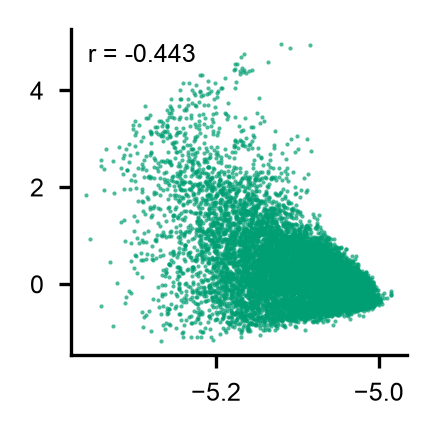

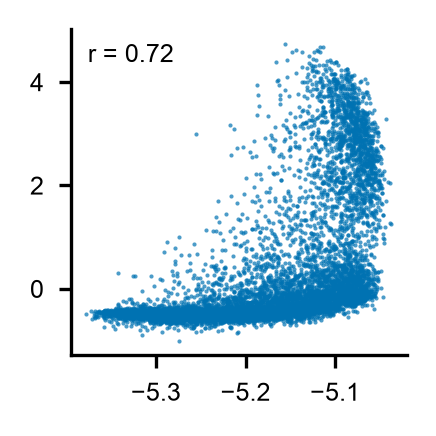

In [11]:
# sum columns of OT_plan restricted to each tissue to correlate these marginal weights with the expression of markers in the tissue cells.
# This will give us an idea of which markers are associated with the homing niche for each tissue.
dominant_fate = np.argmax(fate_matrix, axis=1)
for tissue in target_names:
    tissue_mask = target_locations[selected_target_mask] == tissue
    # subset rows of OT_plan to only those that correspond to blood cells with dominant fate belonging to tissue
    dominant_fate_mask = dominant_fate == target_names.index(tissue)
    # subset OT_plan to only those rows
    OT_plan_dominant = OT_plan[fate_matrix[:, target_names.index(tissue)] > 1 / 3, :]
    landing_mass_homing_score = OT_plan[:, tissue_mask].sum(axis=0)
    data_target_tissue = data_target[selected_target_mask][tissue_mask, :]

    # correlate this with the expression of every marker of these tissue cells
    correlation_with_expression = np.array(
        [
            np.corrcoef(landing_mass_homing_score, data_target_tissue[:, i])[0, 1]
            for i in range(data_target_tissue.shape[1])
        ]
    )

    correlation_with_expression = np.array(
        [
            spearmanr(np.log10(landing_mass_homing_score), data_target_tissue[:, i])[0]
            for i in range(data_target_tissue.shape[1])
        ]
    )
    # sort adata.var_names by the same order
    adata_var_names_sorted = adata.var_names[
        np.argsort(np.abs(correlation_with_expression))[::-1]
    ]
    # sort correlation_with_expression by absolute value
    correlation_with_expression = correlation_with_expression[
        np.argsort(np.abs(correlation_with_expression))[::-1]
    ]

    plt.figure(figsize=(7.4 * cm, 3.4 * cm), layout="constrained")
    plt.axhline(0, color="dimgray", linestyle="solid", linewidth=0.8, alpha=1)
    plt.bar(
        adata_var_names_sorted, correlation_with_expression, color=tissue_colors[tissue]
    )
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.xticks(rotation=90)
    plt.ylim(-1, 1)
    plt.xlim(-0.5, len(adata_var_names_sorted) - 0.5)
    plt.yticks([-1, -0.5, 0, 0.5, 1])
    plt.savefig(
        figure_path
        + "marginal_mass_homing_correlation_"
        + tissue
        + "_"
        + str(replicate_id)
        + ".pdf"
    )
    plt.close()

    if tissue == "Colon":
        # plot scatter plot of landing_mass_homing_score vs expression of CD69
        plt.figure(figsize=(3.4 * cm, 3.4 * cm), layout="constrained")
        plt.scatter(
            np.log10(landing_mass_homing_score),
            data_target_tissue[:, adata.var_names.get_loc("CD69")],
            color=tissue_colors[tissue],
            s=1,
            alpha=0.7,
            edgecolor=None,
            linewidth=0,
            rasterized=True,
        )
        # plt.xlabel('log10(Landing Mass Homing Score)')
        # plt.ylabel('CD69 Expression')
        plt.gca().spines["top"].set_visible(False)
        plt.gca().spines["right"].set_visible(False)
        # plot regression line and pearson correlation coefficient
        # m, b = np.polyfit(np.log10(landing_mass_homing_score), data_target_tissue[:, adata.var_names.get_loc('CD69')], 1)
        # plt.plot(np.log10(landing_mass_homing_score), m*np.log10(landing_mass_homing_score) + b, color='dimgray', linewidth=0.8)
        plt.text(
            0.05,
            0.9,
            f"r = {np.round(spearmanr(np.log10(landing_mass_homing_score), data_target_tissue[:, adata.var_names.get_loc('CD69')])[0], 3)}",
            transform=plt.gca().transAxes,
        )
        plt.savefig(
            figure_path
            + "landing_mass_homing_score_vs_CD69_"
            + tissue
            + "_"
            + str(replicate_id)
            + ".pdf",
            dpi=600,
        )
        plt.show()

    if tissue == "Tonsil":
        # same but with CCR7
        plt.figure(figsize=(3.4 * cm, 3.4 * cm), layout="constrained")
        plt.scatter(
            np.log10(landing_mass_homing_score),
            data_target_tissue[:, adata.var_names.get_loc("CCR7")],
            color=tissue_colors[tissue],
            s=1,
            alpha=0.7,
            edgecolor=None,
            linewidth=0,
            rasterized=True,
        )
        # plt.xlabel('log10(Landing Mass Homing Score)')
        # plt.ylabel('CCR7 Expression')
        plt.gca().spines["top"].set_visible(False)
        plt.gca().spines["right"].set_visible(False)
        # plot regression line and pearson correlation coefficient
        # m, b = np.polyfit(np.log10(landing_mass_homing_score), data_target_tissue[:, adata.var_names.get_loc('CCR7')], 1)
        # plt.plot(np.log10(landing_mass_homing_score), m*np.log10(landing_mass_homing_score) + b, color='dimgray', linewidth=0.8)
        plt.text(
            0.05,
            0.9,
            f"r = {np.round(spearmanr(np.log10(landing_mass_homing_score), data_target_tissue[:, adata.var_names.get_loc('CCR7')])[0], 3)}",
            transform=plt.gca().transAxes,
        )
        plt.savefig(
            figure_path
            + "landing_mass_homing_score_vs_CCR7_"
            + tissue
            + "_"
            + str(replicate_id)
            + ".pdf",
            dpi=600,
        )
        plt.show()